# Does Home Field Advantage Exist in the NFL?

**Question:** How much does playing at home help NFL teams, and did it shrink in 2020 when stadiums were mostly empty?

Steps: pull data → clean → load into Postgres (`nfl` schema) → answer with SQL → chart.

## 1. Pull the data
Every NFL game 2015–2025 from nflverse. 2026 is still in progress, so it is left out.

In [1]:
import os
import nflreadpy as nfl
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

os.makedirs("data", exist_ok=True)
seasons = list(range(2015, 2026))   # 2015 through 2025
games = nfl.load_schedules(seasons).to_pandas()   # nflreadpy returns Polars; convert to pandas
games.to_csv("data/raw_schedules.csv", index=False)
print(games.shape)
games[["season", "game_type", "week", "away_team", "home_team", "away_score", "home_score", "location"]].head()

(3028, 46)


,season,game_type,week,away_team,home_team,away_score,home_score,location
0,2015,REG,1,PIT,NE,21,28,Home
1,2015,REG,1,IND,BUF,14,27,Home
2,2015,REG,1,GB,CHI,31,23,Home
3,2015,REG,1,KC,HOU,27,20,Home
4,2015,REG,1,CAR,JAX,20,9,Home


## 2. Clean the data
| Rule | Why |
| --- | --- |
| Regular season only | Playoff home teams are the better teams, which skews results |
| Drop neutral sites | Nobody is really "home" (London, Mexico City) |
| Drop ties | Not a win or a loss |
| Merge moved teams (OAK→LV, SD→LAC, STL→LA) | One name per team across all years |

In [2]:
df = games[(games["game_type"] == "REG") & (games["location"] == "Home")].copy()
df = df.dropna(subset=["home_score", "away_score"])      # unplayed games
df = df[df["home_score"] != df["away_score"]]            # drop ties

team_map = {"OAK": "LV", "SD": "LAC", "STL": "LA"}
df["home_team"] = df["home_team"].replace(team_map)
df["away_team"] = df["away_team"].replace(team_map)

df["home_win"] = (df["home_score"] > df["away_score"]).astype(int)   # 1 = home won
df["margin"] = df["home_score"] - df["away_score"]                  # +7 = home won by 7
df["covid_season"] = (df["season"] == 2020).astype(int)              # 1 = mostly empty stadiums

clean = df[["game_id", "season", "week", "gameday", "home_team", "away_team",
            "home_score", "away_score", "home_win", "margin", "roof", "covid_season"]]
clean.to_csv("data/clean_games.csv", index=False)
print(len(clean), "games")
print("Home win %:", round(clean["home_win"].mean() * 100, 1))
print(len(clean["home_team"].unique()), "teams")

2837 games
Home win %: 54.6
32 teams


## 3. Load into the database
The login lives in a private `.env` file (`DB_URL=...`) that is never uploaded. The games go in their own `nfl` schema, apart from other tables.

In [3]:
load_dotenv()
engine = create_engine(os.environ["DB_URL"])
with engine.begin() as conn:
    conn.execute(text("CREATE SCHEMA IF NOT EXISTS nfl"))
clean.to_sql("games", engine, schema="nfl", if_exists="replace", index=False)
pd.read_sql("SELECT COUNT(*) AS games FROM nfl.games", engine)

,games
0,2837


## 4. Answer the questions with SQL
Each query lives in [`sql/`](sql/).

In [4]:
def run(file):
    with open(f"sql/{file}") as f:
        return pd.read_sql(f.read(), engine)

overall = run("01_overall.sql")
by_season = run("02_by_season.sql")
covid = run("03_covid_vs_normal.sql")
teams = run("04_team_home_boost.sql")
overall

,games,home_win_pct,avg_home_margin
0,2837,54.6,1.8


In [5]:
by_season

,season,games,home_win_pct,avg_home_margin
0,2015,253,53.8,1.5
1,2016,251,57.8,2.6
2,2017,251,57.0,2.5
3,2018,251,60.6,2.4
4,2019,250,52.0,0.0
5,2020,252,50.4,0.1
6,2021,268,51.1,1.6
7,2022,263,56.7,2.1
8,2023,267,55.8,2.7
9,2024,267,52.4,1.7


In [6]:
covid

,period,games,home_win_pct
0,Normal seasons,2585,55.0
1,2020 (few fans),252,50.4


In [7]:
teams.head(10)

,team,home_win_pct,away_win_pct,home_boost
0,MIA,62.5,36.4,26.1
1,CLE,46.6,23.6,23.0
2,GB,71.6,52.3,19.3
3,DEN,57.1,38.6,18.5
4,BUF,71.9,54.0,17.9
5,CAR,48.3,34.4,13.9
6,JAX,43.2,29.5,13.7
7,NYJ,38.9,26.4,12.5
8,NYG,39.3,27.3,12.1
9,IND,53.3,41.4,12.0


## 5. Charts

In [8]:
BLUE, ORANGE, INK, MUTED, GRID = "#2A5DB0", "#D9622B", "#1F2937", "#6B7280", "#E5E7EB"
plt.rcParams.update({"font.size": 11, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlecolor": INK})
os.makedirs("charts", exist_ok=True)

def tidy(ax):
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(length=0)

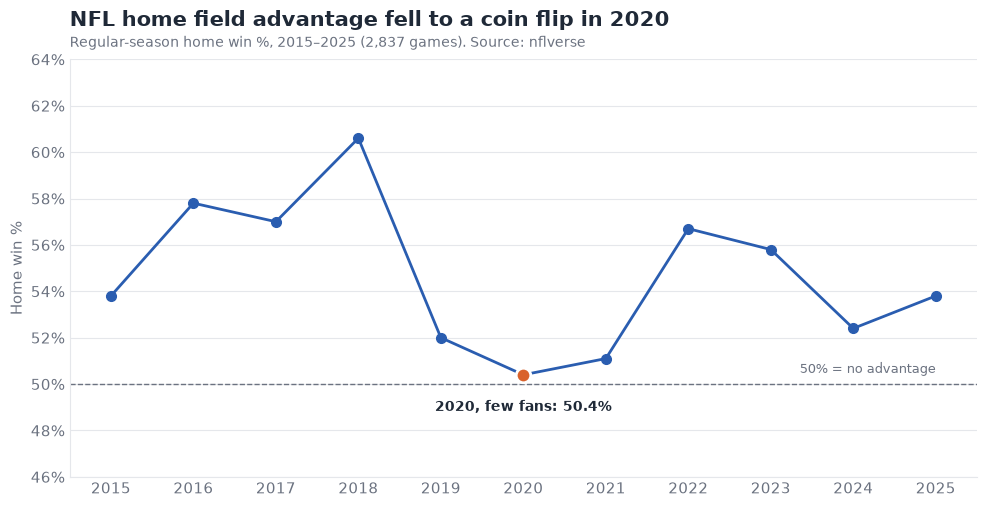

In [9]:
# Chart 1: home win % by season, 2020 highlighted
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.axhline(50, ls="--", color=MUTED, lw=1)
ax.text(2025, 50.35, "50% = no advantage", color=MUTED, ha="right", va="bottom", fontsize=9)
ax.plot(by_season["season"], by_season["home_win_pct"], color=BLUE, lw=2, marker="o", ms=7)
r = by_season[by_season["season"] == 2020].iloc[0]
ax.scatter([2020], [r.home_win_pct], color=ORANGE, s=110, zorder=3, edgecolor="white", lw=2)
ax.annotate(f"2020, few fans: {r.home_win_pct:.1f}%", (2020, r.home_win_pct), xytext=(0, -26),
            textcoords="offset points", ha="center", color=INK, fontsize=10, fontweight="bold")
ax.set_ylim(46, 64); ax.set_yticks(range(46, 65, 2))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_xticks(by_season["season"]); ax.set_xlim(2014.5, 2025.5)
ax.set_ylabel("Home win %")
ax.set_title("NFL home field advantage fell to a coin flip in 2020", loc="left", fontsize=15, fontweight="bold", pad=24)
ax.text(0, 1.03, "Regular-season home win %, 2015–2025 (2,837 games). Source: nflverse",
        transform=ax.transAxes, color=MUTED, fontsize=10)
tidy(ax); plt.tight_layout(); plt.savefig("charts/01_home_win_by_season.png", dpi=200); plt.show()

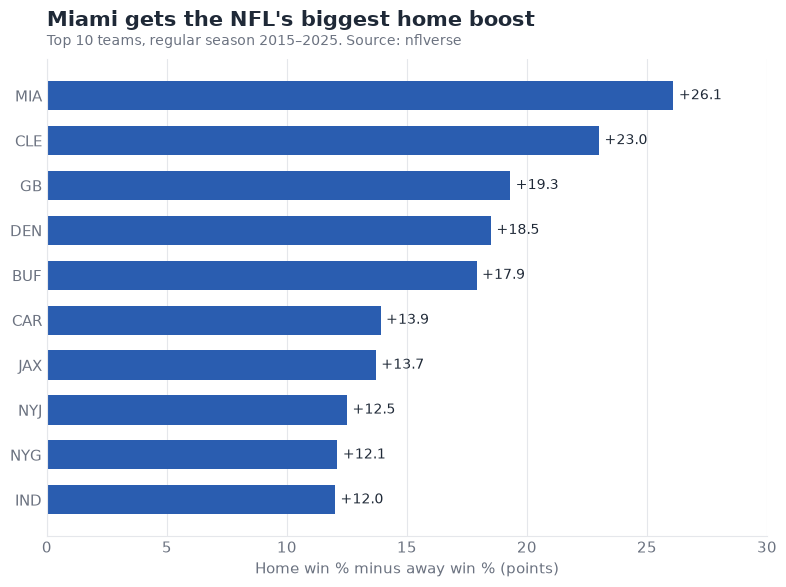

In [10]:
# Chart 2: top 10 teams by home boost
top10 = teams.head(10).sort_values("home_boost")
fig, ax = plt.subplots(figsize=(8, 6))
ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
bars = ax.barh(top10["team"], top10["home_boost"], color=BLUE, height=0.65)
ax.bar_label(bars, fmt="+%.1f", padding=4, color=INK, fontsize=10)
ax.set_xlim(0, top10["home_boost"].max() * 1.15)
ax.set_xlabel("Home win % minus away win % (points)")
ax.set_title("Miami gets the NFL's biggest home boost", loc="left", fontsize=15, fontweight="bold", pad=24)
ax.text(0, 1.03, "Top 10 teams, regular season 2015–2025. Source: nflverse",
        transform=ax.transAxes, color=MUTED, fontsize=10)
tidy(ax); plt.tight_layout(); plt.savefig("charts/02_top10_home_boost.png", dpi=200); plt.show()

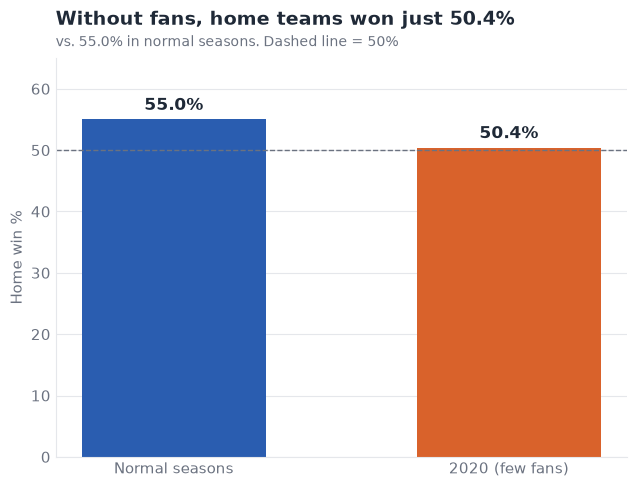

In [11]:
# Chart 3: 2020 vs normal seasons (bars start at 0 so the gap isn't exaggerated)
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
bars = ax.bar(covid["period"], covid["home_win_pct"], color=[BLUE, ORANGE], width=0.55)
ax.bar_label(bars, fmt="%.1f%%", padding=4, color=INK, fontsize=12, fontweight="bold")
ax.axhline(50, ls="--", color=MUTED, lw=1)
ax.set_ylim(0, 65); ax.set_ylabel("Home win %")
ax.set_title("Without fans, home teams won just 50.4%", loc="left", fontsize=14, fontweight="bold", pad=24)
ax.text(0, 1.03, "vs. 55.0% in normal seasons. Dashed line = 50%", transform=ax.transAxes, color=MUTED, fontsize=10)
tidy(ax); plt.tight_layout(); plt.savefig("charts/03_covid_vs_normal.png", dpi=200); plt.show()

## Findings
- Home teams won **54.6%** of 2,837 regular-season games (2015–2025), by **1.8 points** on average.
- In 2020, with mostly empty stadiums, that fell to **50.4%** (a coin flip), vs **55.0%** in normal seasons. It was already low in 2019 (52.0%), so fans are likely part of the story, not all of it.
- **Miami** has the biggest home boost: **62.5%** at home vs **36.4%** away. Seattle and Arizona actually did slightly better on the road.